# Movie Recommender — Analysis & Modelling

**Goal:** recommend movies a user will enjoy, using three approaches and comparing them fairly:

1. **Content-based filtering** (core task) — "movies *like this one*", from genres, keywords, cast, director and plot (TMDB 5000).
2. **User-based collaborative filtering** (bonus) — "users *like you* liked…", from real ratings (MovieLens).
3. **Hybrid** (bonus) — a weighted blend of the two, with the weight chosen by offline evaluation.

Outputs used by the Flask app (`app.py`): `model.pkl` (movie table), `similarity.pkl` (content
neighbours) and `hybrid.pkl` (TF-IDF matrix + collaborative item factors + tuned blend weight).

Reusable logic (parsing, tag building, scoring) lives in `recommender.py` so the app runs exactly
what was evaluated here.

In [1]:
import pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import recommender as rec

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

## 1. Load and explore the TMDB data

Two files: `tmdb_5000_movies.csv` (one row per film: genres, keywords, overview, votes…) and
`tmdb_5000_credits.csv` (cast and crew). Several columns hold **JSON stored as text**, e.g.
`[{"id": 28, "name": "Action"}, …]`, which we'll need to parse.

> **Data note:** the credits file supplied with the course starter code was damaged — it only had
> 1,492 of the 4,803 films (the rest were blank rows), so two-thirds of movies would have had no cast
> or director. This repo uses the complete original Kaggle file (4,803 rows).

In [2]:
movies_raw = pd.read_csv("data/tmdb_5000_movies.csv")
credits_raw = pd.read_csv("data/tmdb_5000_credits.csv")
print(movies_raw.shape, credits_raw.shape)
movies_raw[["id", "title", "genres", "keywords", "vote_average", "vote_count"]].head(3)

(4803, 20) (4803, 4)


,id,title,genres,keywords,vote_average,vote_count
0,19995,Avatar,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","[{""id"": 1463, ""name"": ""culture clash""}, {""id"": 2964, ""name"": ""future""}, {""id...",7.2,11800
1,285,Pirates of the Caribbean: At World's End,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""name"": ""Fantasy""}, {""id"": 28, ...","[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""name"": ""drug abuse""}, {""id"": 911...",6.9,4500
2,206647,Spectre,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adventure""}, {""id"": 80, ""...","[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name"": ""based on novel""}, {""id"": 4...",6.3,4466


In [3]:
# Why merge on id, not title (the starter merged on title)?
dupes = movies_raw[movies_raw.title.duplicated(keep=False)][["id", "title", "release_date"]]
print("Titles shared by different films:"); display(dupes)
print("rows after merging on title:", len(movies_raw.merge(credits_raw, on="title")),
      "| on id:", len(movies_raw.merge(credits_raw, left_on="id", right_on="movie_id")))

Titles shared by different films:


,id,title,release_date
972,72710,The Host,2013-03-22
1359,268,Batman,1989-06-23
2877,1255,The Host,2006-07-27
3647,39269,Out of the Blue,1980-05-01
3693,10844,Out of the Blue,2006-10-12
4267,2661,Batman,1966-07-30


rows after merging on title: 4809 | on id: 4803


Merging on title creates **fake rows** (each "Batman" gets matched with both Batman cast lists),
so we merge on the numeric `id`. Now build the clean table with `rec.load_movies()`, which:
parses the JSON columns, keeps the **top 3 cast** and the **director**, collapses multi-word names into
single tokens (`Sam Worthington → samworthington`), and builds a `tags` string from
overview + genres + keywords + cast + director, then stems it.

Each field gets a **weight** (repeating a token raises its weight): overview ×1, genres / keywords / cast ×2,
director ×3. Without this the long plot text drowns out the short-but-informative metadata. The weights
were chosen with the offline evaluation in section 4, where they're compared against equal weights.

> The starter notebook also built the tags *without* genres, even though it parsed them — fixed here.

In [4]:
movies = rec.load_movies()
print(movies.shape)
movies[["title", "year", "genres", "cast", "director"]].head()

(4803, 11)


,title,year,genres,cast,director
0,Avatar,2009,"[Action, Adventure, Fantasy, Science Fiction]","[Sam Worthington, Zoe Saldana, Sigourney Weaver]",[James Cameron]
1,Pirates of the Caribbean: At World's End,2007,"[Adventure, Fantasy, Action]","[Johnny Depp, Orlando Bloom, Keira Knightley]",[Gore Verbinski]
2,Spectre,2015,"[Action, Adventure, Crime]","[Daniel Craig, Christoph Waltz, Léa Seydoux]",[Sam Mendes]
3,The Dark Knight Rises,2012,"[Action, Crime, Drama, Thriller]","[Christian Bale, Michael Caine, Gary Oldman]",[Christopher Nolan]
4,John Carter,2012,"[Action, Adventure, Science Fiction]","[Taylor Kitsch, Lynn Collins, Samantha Morton]",[Andrew Stanton]


In [5]:
print("Example tags (Avatar):\n", movies.loc[0, "tags"][:400], "...")

Example tags (Avatar):
 in the 22nd century, a parapleg marin is dispatch to the moon pandora on a uniqu mission, but becom torn between follow order and protect an alien civilization. action adventur fantasi sciencefict action adventur fantasi sciencefict cultureclash futur spacewar spacecoloni societi spacetravel futurist romanc space alien tribe alienplanet cgi marin soldier battl loveaffair antiwar powerrel mindandso ...


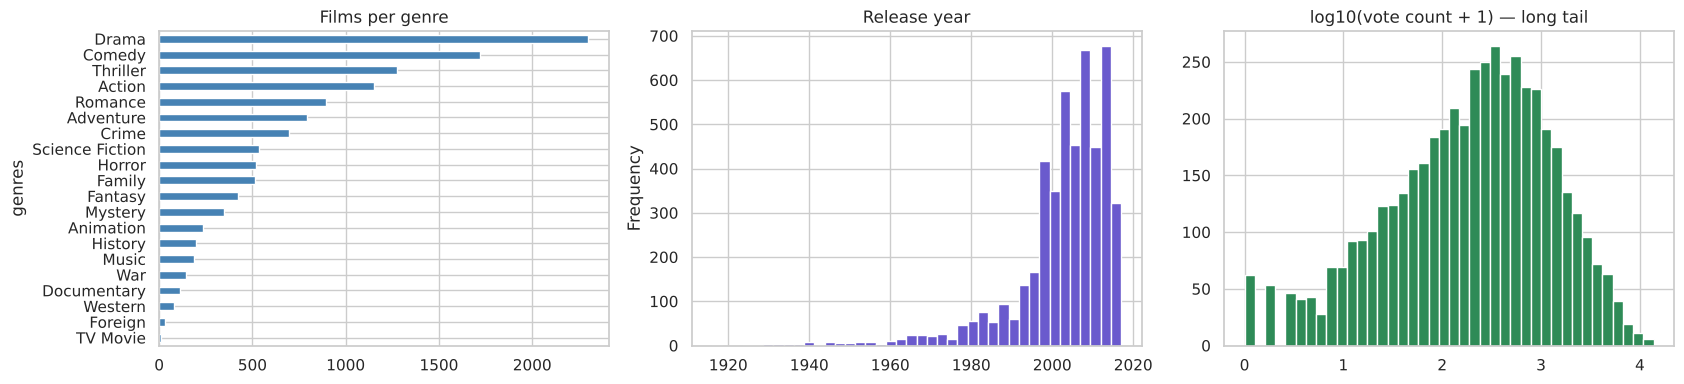

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
movies.explode("genres")["genres"].value_counts().plot.barh(ax=axes[0], color="steelblue")
axes[0].invert_yaxis(); axes[0].set_title("Films per genre")
movies["year"].dropna().astype(int).plot.hist(bins=40, ax=axes[1], color="slateblue")
axes[1].set_title("Release year")
axes[2].hist(np.log10(movies["vote_count"] + 1), bins=40, color="seagreen")
axes[2].set_title("log10(vote count + 1) — long tail")
plt.tight_layout(); plt.show()

**Observations**
- Drama, Comedy, Thriller and Action dominate; a film can have several genres.
- Mostly films from 1990–2016.
- Vote counts follow a **long tail**: a few blockbusters have >10k votes, many films have very few.
  A raw `vote_average` is unreliable for low-count films (one 10/10 vote = "best film ever").

### A popularity baseline: IMDB weighted rating
Before personalising, the simplest recommender is "show everyone the best films". To rank fairly we
shrink each film's average towards the global mean, in proportion to how few votes it has:

$$WR = \frac{v}{v+m}R + \frac{m}{v+m}C$$

where $R$ = film's average, $v$ = its vote count, $C$ = mean of all films, $m$ = minimum votes (90th percentile).

In [7]:
C_ = movies.vote_average.mean(); m_ = movies.vote_count.quantile(0.90)
movies["weighted_rating"] = (movies.vote_count / (movies.vote_count + m_) * movies.vote_average
                             + m_ / (movies.vote_count + m_) * C_)
movies.sort_values("weighted_rating", ascending=False)[["title", "year", "vote_average", "vote_count", "weighted_rating"]].head(10).round(2)

,title,year,vote_average,vote_count,weighted_rating
1881,The Shawshank Redemption,1994,8.5,8205,8.06
662,Fight Club,1999,8.3,9413,7.94
65,The Dark Knight,2008,8.2,12002,7.92
3232,Pulp Fiction,1994,8.3,8428,7.90
96,Inception,2010,8.1,13752,7.86
3337,The Godfather,1972,8.4,5893,7.85
95,Interstellar,2014,8.1,10867,7.81
809,Forrest Gump,1994,8.2,7927,7.80
329,The Lord of the Rings: The Return of the King,2003,8.1,8064,7.73
1990,The Empire Strikes Back,1980,8.2,5879,7.70


## 2. Content-based filtering

**Idea:** represent each film as a vector of its tag words, then recommend the films whose vectors
point in the most similar direction (**cosine similarity** — 1 = identical tag mix, 0 = nothing in common;
it ignores vector length, so a film with a long overview isn't favoured).

Two ways to turn text into vectors:
- **CountVectorizer** (bag of words): counts each word.
- **TF-IDF**: down-weights words that appear in many films ("film", "life") and up-weights distinctive
  ones ("hobbit", "christophernolan").

We'll try both, look at the results, and later compare them quantitatively using real user ratings.

In [8]:
count_vec = CountVectorizer(max_features=5000, stop_words="english")
X_count = count_vec.fit_transform(movies["tags"])
tfidf_vec = TfidfVectorizer(max_features=5000, stop_words="english", sublinear_tf=True)
X_tfidf = tfidf_vec.fit_transform(movies["tags"])
print("matrix shape:", X_tfidf.shape, "| non-zero share: %.3f%%" % (100 * X_tfidf.nnz / np.prod(X_tfidf.shape)))

sim_count = cosine_similarity(X_count)
sim_tfidf = cosine_similarity(X_tfidf)
print("full similarity matrix:", sim_tfidf.shape, f"= {sim_tfidf.nbytes / 1e6:.0f} MB in memory")

matrix shape: (4803, 5000) | non-zero share: 0.595%


full similarity matrix: (4803, 4803) = 185 MB in memory


In [9]:
title_to_idx = pd.Series(movies.index, index=movies["title"]).groupby(level=0).first()

def recommend(title, sim, n=10):
    idx = title_to_idx[title]
    order = np.argsort(-sim[idx])
    order = [i for i in order if i != idx][:n]
    return movies.loc[order, ["title", "year", "genres"]].assign(similarity=sim[idx, order].round(3)).reset_index(drop=True)

for t in ["The Dark Knight Rises", "Inception", "Toy Story"]:
    print(f"\n=== Because you liked {t} (TF-IDF) ==="); display(recommend(t, sim_tfidf))


=== Because you liked The Dark Knight Rises (TF-IDF) ===


,title,year,genres,similarity
0,The Dark Knight,2008,"[Drama, Action, Crime, Thriller]",0.483
1,Batman Begins,2005,"[Action, Crime, Drama]",0.422
2,Batman Returns,1992,"[Action, Fantasy]",0.293
3,Batman Forever,1995,"[Action, Crime, Fantasy]",0.250
4,Batman,1989,"[Fantasy, Action]",0.249
5,Batman & Robin,1997,"[Action, Crime, Fantasy]",0.246
6,Batman v Superman: Dawn of Justice,2016,"[Action, Adventure, Fantasy]",0.207
7,The Prestige,2006,"[Drama, Mystery, Thriller]",0.176
8,"Batman: The Dark Knight Returns, Part 2",2013,"[Action, Animation]",0.168
9,Kick-Ass 2,2013,"[Action, Adventure, Crime]",0.160



=== Because you liked Inception (TF-IDF) ===


,title,year,genres,similarity
0,The East,2013,"[Drama, Thriller]",0.169
1,12 Rounds,2009,"[Action, Adventure, Drama, Thriller]",0.148
2,The Prestige,2006,"[Drama, Mystery, Thriller]",0.146
3,Memento,2000,"[Mystery, Thriller]",0.142
4,Insomnia,2002,"[Crime, Mystery, Thriller]",0.142
5,The Helix... Loaded,2005,"[Action, Comedy, Science Fiction]",0.138
6,Don Jon,2013,"[Romance, Comedy, Drama]",0.123
7,The Count of Monte Cristo,2002,"[Action, Adventure, Drama, Thriller]",0.119
8,Premium Rush,2012,"[Crime, Action, Thriller]",0.118
9,The Walk,2015,"[Adventure, Drama, Thriller]",0.116



=== Because you liked Toy Story (TF-IDF) ===


,title,year,genres,similarity
0,Toy Story 2,1999,"[Animation, Comedy, Family]",0.500
1,Toy Story 3,2010,"[Animation, Family, Comedy]",0.417
2,Cars 2,2011,"[Animation, Family, Adventure, Comedy]",0.216
3,Child's Play,1988,"[Horror, Thriller]",0.210
4,Small Soldiers,1998,"[Comedy, Adventure, Fantasy, Science Fiction, Action]",0.192
5,Cars,2006,"[Animation, Adventure, Comedy, Family]",0.186
6,The Santa Clause 2,2002,"[Fantasy, Comedy, Family]",0.184
7,The Indian in the Cupboard,1995,"[Adventure, Family, Fantasy]",0.167
8,Monster House,2006,"[Animation, Comedy, Family, Fantasy]",0.156
9,The Lego Movie,2014,"[Adventure, Animation, Comedy, Family, Fantasy]",0.154


In [10]:
print("CountVectorizer for comparison:"); recommend("The Dark Knight Rises", sim_count)

CountVectorizer for comparison:


,title,year,genres,similarity
0,The Dark Knight,2008,"[Drama, Action, Crime, Thriller]",0.545
1,Batman Begins,2005,"[Action, Crime, Drama]",0.456
2,Batman Returns,1992,"[Action, Fantasy]",0.310
3,Batman & Robin,1997,"[Action, Crime, Fantasy]",0.303
4,Amidst the Devil's Wings,2014,"[Drama, Action, Crime]",0.300
5,Nighthawks,1981,"[Action, Crime, Thriller]",0.283
6,Exiled,2006,"[Action, Crime, Thriller]",0.270
7,Batman,1989,"[Fantasy, Action]",0.267
8,Batman Forever,1995,"[Action, Crime, Fantasy]",0.264
9,Romeo Is Bleeding,1993,"[Action, Crime, Drama, Thriller]",0.263


Both give sensible results — Batman films, Nolan films, superhero films. TF-IDF tends to rank the
*distinctive* matches (same director/franchise) higher. A known weakness of content-based filtering
is visible: it recommends "more of the same" and knows nothing about **quality** or what real people
enjoy together — which is what collaborative filtering adds.

### 2.1 Save the content-based model
The full 4,803 × 4,803 matrix is ~185 MB — over GitHub's 100 MB file limit, and the app only ever shows
the top results. So `similarity.pkl` stores each film's **top 50 neighbours and scores** (~2 MB). The
recommendations are identical. (We save TF-IDF; section 4 confirms it's the better choice.)

In [11]:
neighbours = rec.top_k_neighbours(sim_tfidf, k=50)
pickle.dump(movies.drop(columns=["tags"]), open("model.pkl", "wb"))
pickle.dump(neighbours, open("similarity.pkl", "wb"))
import os; print({f: f"{os.path.getsize(f) / 1e6:.1f} MB" for f in ["model.pkl", "similarity.pkl"]})

{'model.pkl': '2.3 MB', 'similarity.pkl': '1.9 MB'}


In [12]:
# Step 4 of the brief: a recommendation function that works from the SAVED files
movies_saved = pickle.load(open("model.pkl", "rb")); sim_saved = pickle.load(open("similarity.pkl", "rb"))

def Recommendation_system(movie_title, n=10):
    idx = movies_saved.index[movies_saved.title == movie_title][0]
    return movies_saved.loc[sim_saved["indices"][idx, :n], "title"].tolist()

Recommendation_system("Avatar")

['Aliens',
 'Star Trek Into Darkness',
 'Cargo',
 'Alien³',
 'Predators',
 'Falcon Rising',
 'A Monster in Paris',
 'Galaxina',
 'The Book of Life',
 'Barbarella']

## 3. Collaborative filtering (bonus)

Content-based needs item features; **collaborative filtering** needs only *who rated what*.
TMDB has no per-user ratings, so we use **MovieLens latest-small** (GroupLens): 100,836 ratings
(0.5–5 stars) from 610 users on 9,742 films. Its `links.csv` maps every film to its **TMDB id**, which
is what makes a hybrid with our content model possible.

100,836 ratings | 610 users | 9,724 films | sparsity = 98.30%


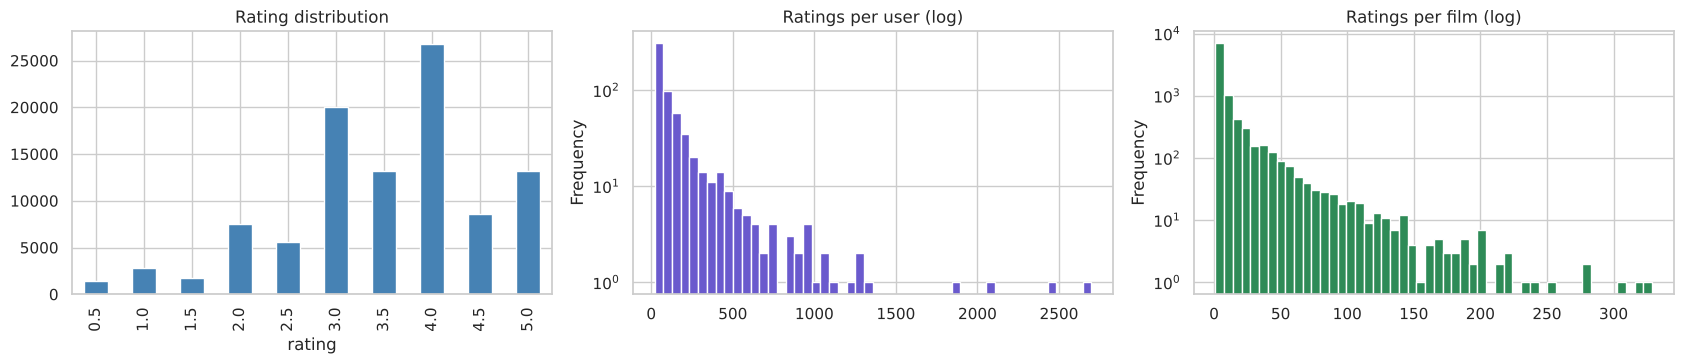

In [13]:
ratings = pd.read_csv("data/movielens/ratings.csv")
links = pd.read_csv("data/movielens/links.csv").dropna(subset=["tmdbId"]).drop_duplicates("tmdbId")
ml_movies = pd.read_csv("data/movielens/movies.csv")
n_users, n_items = ratings.userId.nunique(), ratings.movieId.nunique()
print(f"{len(ratings):,} ratings | {n_users} users | {n_items:,} films | sparsity = {1 - len(ratings) / (n_users * n_items):.2%}")

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
ratings.rating.value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue"); axes[0].set_title("Rating distribution")
ratings.groupby("userId").size().plot.hist(bins=50, ax=axes[1], log=True, color="slateblue"); axes[1].set_title("Ratings per user (log)")
ratings.groupby("movieId").size().plot.hist(bins=50, ax=axes[2], log=True, color="seagreen"); axes[2].set_title("Ratings per film (log)")
plt.tight_layout(); plt.show()

The user–item matrix is **98% empty** — the central challenge of collaborative filtering. People rate
generously (mode = 4 stars) and some users rate far more than others, so each user's *personal scale*
matters: a 3 from a harsh critic may mean more than a 4 from someone who gives everything 4.

### 3.1 Task: predict ratings — evaluation set-up
Random 80/20 split of ratings. Metric: **RMSE** in stars on the held-out 20% (lower is better).

In [14]:
from sklearn.model_selection import train_test_split
train_r, test_r = train_test_split(ratings, test_size=0.2, random_state=42)

def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))
results = []

# Baselines
gm = train_r.rating.mean()
results.append(("Global mean", rmse(test_r.rating, np.full(len(test_r), gm))))
user_mean = train_r.groupby("userId").rating.mean()
results.append(("User mean", rmse(test_r.rating, test_r.userId.map(user_mean).fillna(gm))))
pd.DataFrame(results, columns=["model", "RMSE"])

,model,RMSE
0,Global mean,1.048841
1,User mean,0.949747


### 3.2 User-based CF from scratch (mean-centred cosine ≈ Pearson correlation)
1. Build the user × film matrix and **subtract each user's mean** (removes the "generous vs harsh" effect).
   Cosine similarity of mean-centred vectors is essentially the **Pearson correlation** between users.
2. To predict user *u*'s rating of film *i*: take the *k* most similar users who rated *i*, and average
   their (mean-centred) ratings weighted by similarity, then add back *u*'s mean:

$$\hat r_{ui} = \bar r_u + \frac{\sum_{v \in N_k(u,i)} \text{sim}(u,v)\,(r_{vi} - \bar r_v)}{\sum_{v} |\text{sim}(u,v)|}$$

In [15]:
users = np.sort(ratings.userId.unique()); items = np.sort(ratings.movieId.unique())
u_ix = {u: i for i, u in enumerate(users)}; i_ix = {m: j for j, m in enumerate(items)}

R = np.full((len(users), len(items)), np.nan)
R[train_r.userId.map(u_ix), train_r.movieId.map(i_ix)] = train_r.rating
mu = np.nanmean(R, axis=1)
Rc = np.nan_to_num(R - mu[:, None])            # mean-centred, unrated = 0
norms = np.linalg.norm(Rc, axis=1) + 1e-9
user_sim = (Rc @ Rc.T) / np.outer(norms, norms)
np.fill_diagonal(user_sim, 0)
rated = ~np.isnan(R)

def predict_user_based(u, i, k=30):
    cand = np.flatnonzero(rated[:, i])          # users who rated film i
    if len(cand) == 0: return mu[u]
    top = cand[np.argsort(-user_sim[u, cand])[:k]]
    s = user_sim[u, top]
    if np.abs(s).sum() < 1e-9: return mu[u]
    return float(np.clip(mu[u] + s @ Rc[top, i] / np.abs(s).sum(), 0.5, 5))

t0 = time.time()
known = test_r.movieId.isin(i_ix)
pred = np.where(known, [predict_user_based(u_ix[u], i_ix.get(m, 0)) if k_ else 0
                        for u, m, k_ in zip(test_r.userId, test_r.movieId, known)], test_r.userId.map(user_mean))
results.append(("User-based CF (from scratch, k=30, Pearson)", rmse(test_r.rating, pred)))
print(f"{time.time() - t0:.0f}s"); pd.DataFrame(results, columns=["model", "RMSE"])

1s


,model,RMSE
0,Global mean,1.048841
1,User mean,0.949747
2,"User-based CF (from scratch, k=30, Pearson)",0.884407


### 3.3 The `surprise` library: KNN and SVD
- **KNNBasic / KNNWithMeans (user-based)** — the same neighbourhood idea, library-implemented.
- **SVD (matrix factorisation)** — learns a short vector of hidden "taste factors" for every user and
  every film (e.g. *how much action*, *how arty*) such that `user · film + biases ≈ rating`. This is the
  approach that won the Netflix Prize. The learned **film factors** also tell us which films are liked by
  the same people — we'll reuse them in the hybrid.

In [16]:
from surprise import Dataset, Reader, KNNBasic, KNNWithMeans, SVD, BaselineOnly

reader = Reader(rating_scale=(0.5, 5))
trainset = Dataset.load_from_df(train_r[["userId", "movieId", "rating"]], reader).build_full_trainset()
testset = list(test_r[["userId", "movieId", "rating"]].itertuples(index=False, name=None))

algos = {
    "Baseline (user + film biases)": BaselineOnly(verbose=False),
    "surprise KNNBasic (user, cosine)": KNNBasic(k=30, sim_options={"name": "cosine", "user_based": True}, verbose=False),
    "surprise KNNWithMeans (user, Pearson)": KNNWithMeans(k=30, sim_options={"name": "pearson", "user_based": True}, verbose=False),
    "surprise SVD (50 factors)": SVD(n_factors=50, n_epochs=30, lr_all=0.007, reg_all=0.05, random_state=42),
}
for name, algo in algos.items():
    algo.fit(trainset)
    preds = algo.test(testset)
    results.append((name, rmse([p.r_ui for p in preds], [p.est for p in preds])))

cf_results = pd.DataFrame(results, columns=["model", "RMSE"]).sort_values("RMSE").reset_index(drop=True)
cf_results.round(4)

,model,RMSE
0,surprise SVD (50 factors),0.8686
1,Baseline (user + film biases),0.8824
2,"User-based CF (from scratch, k=30, Pearson)",0.8844
3,"surprise KNNWithMeans (user, Pearson)",0.9043
4,User mean,0.9497
5,"surprise KNNBasic (user, cosine)",0.9801
6,Global mean,1.0488


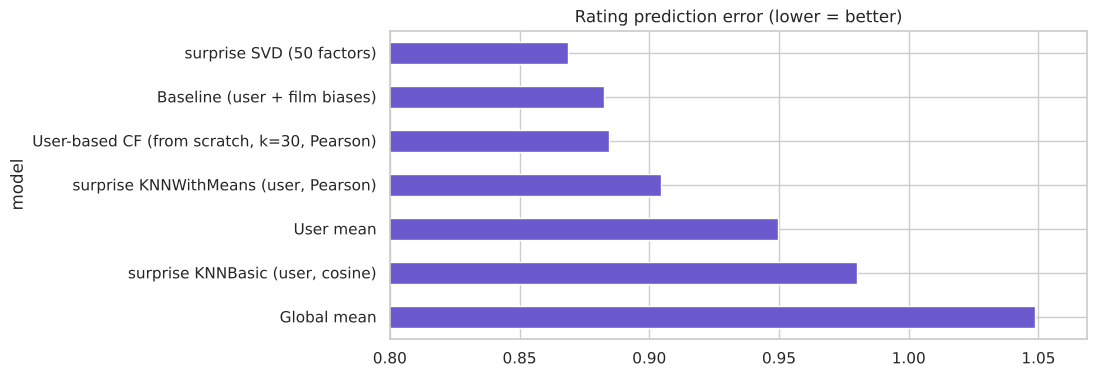

In [17]:
ax = cf_results.set_index("model")["RMSE"].sort_values(ascending=False).plot.barh(figsize=(9, 4), color="slateblue")
ax.set_xlim(0.8, cf_results.RMSE.max() + 0.02); ax.set_title("Rating prediction error (lower = better)"); plt.show()

**Takeaways:** every personalised model beats the global mean. Mean-centring matters (KNNWithMeans /
our Pearson version beat plain-cosine KNNBasic, which is fooled by users' personal scales). Biases
alone get you a long way, and **SVD is best** — it generalises across the sparse matrix instead of
relying on a few overlapping neighbours.

### 3.4 Top-N recommendations for a user (user-based CF)

In [18]:
def recommend_for_user(user_id, n=10, k=30):
    u = u_ix[user_id]
    unseen = np.flatnonzero(~rated[u])
    # vectorised version of predict_user_based over all unseen films
    nbrs = np.argsort(-user_sim[u])[:k]
    s = user_sim[u, nbrs][:, None] * rated[nbrs][:, unseen]
    score = mu[u] + (s * Rc[nbrs][:, unseen]).sum(0) / (np.abs(s).sum(0) + 1e-9)
    support = rated[nbrs][:, unseen].sum(0)
    score[support < 3] = -np.inf                  # need ≥3 neighbours to trust a prediction
    best = unseen[np.argsort(-score)[:n]]
    return ml_movies.set_index("movieId").loc[items[best], ["title", "genres"]].assign(pred=np.sort(score)[::-1][:n].round(2))

uid = 414
print("User", uid, "rated highly:"); display(train_r[train_r.userId == uid].nlargest(5, "rating").merge(ml_movies, on="movieId")[["title", "rating"]])
print("Recommended:"); recommend_for_user(uid)

User 414 rated highly:


,title,rating
0,Goodfellas (1990),5.0
1,Chinatown (1974),5.0
2,Excalibur (1981),5.0
3,Forrest Gump (1994),5.0
4,All the Real Girls (2003),5.0


Recommended:


,title,genres,pred
movieId,,,
3030,Yojimbo (1961),Action|Adventure,5.19
3435,Double Indemnity (1944),Crime|Drama|Film-Noir,4.79
52435,How the Grinch Stole Christmas! (1966),Animation|Comedy|Fantasy|Musical,4.75
3334,Key Largo (1948),Crime|Drama|Film-Noir|Thriller,4.69
1208,Apocalypse Now (1979),Action|Drama|War,4.59
1411,Hamlet (1996),Crime|Drama|Romance,4.58
7022,Battle Royale (Batoru rowaiaru) (2000),Action|Drama|Horror|Thriller,4.57
1247,"Graduate, The (1967)",Comedy|Drama|Romance,4.55
5833,Dog Soldiers (2002),Action|Horror,4.55


## 4. Hybrid recommender (bonus)

Now we combine both worlds. We restrict to the **~3,500 films that are in both TMDB 5000 and MovieLens**
(joined via `tmdbId`), so candidates have both a content vector and collaborative information.

**Scoring a user** from the films they liked (rated ≥ 4) — no rating history needed beyond that:
- **Content score** = cosine similarity between each film's TF-IDF vector and the average vector of the liked films.
- **Collaborative score** — we compare two options:
  - *SVD factors*: cosine similarity in the SVD film-factor space learned in 3.3;
  - *Item-based CF*: `sim(i, j)` = cosine between the **audiences** of two films (which users rated them),
    and a film's score = sum of its similarity to each liked film ("people who watched these also watched…").
- **Hybrid** = `w × collaborative + (1 − w) × content` (both rescaled to 0–1).

This "profile from liked films" design is deliberate: it is exactly what the web app can do for a
**new visitor** who just picks a few favourite films.

### 4.1 Offline evaluation protocol (ranking, not rating)
For each user, sort their ratings by time: the **first 80% is "history"**, the **last 20% is the "future"**.
We recommend 10 films using history only and check how many the user actually went on to rate ≥ 4.
Metrics: **Precision@10**, **Recall@10**, **Hit-rate@10** (≥1 hit). Random and popularity baselines
show what "good" looks like. Everything collaborative is learned from **history only** — no peeking.

In [19]:
ml = ratings.merge(links[["movieId", "tmdbId"]], on="movieId")
ml["tmdbId"] = ml.tmdbId.astype(int)
row_of_tmdb = pd.Series(movies.index, index=movies.id)
ml = ml[ml.tmdbId.isin(row_of_tmdb.index)].copy()
ml["row"] = ml.tmdbId.map(row_of_tmdb).astype(int)
print(f"{len(ml):,} ratings on {ml.row.nunique():,} overlapping films from {ml.userId.nunique()} users")

ml = ml.sort_values(["userId", "timestamp"])
ml["rank"] = ml.groupby("userId").cumcount(); ml["n"] = ml.groupby("userId").userId.transform("size")
hist, future = ml[ml["rank"] < 0.8 * ml["n"]], ml[ml["rank"] >= 0.8 * ml["n"]]
n = len(movies)

# (a) SVD film factors from history
svd_eval = SVD(n_factors=50, n_epochs=30, lr_all=0.007, reg_all=0.05, random_state=42)
svd_eval.fit(Dataset.load_from_df(hist[["userId", "row", "rating"]], reader).build_full_trainset())
F_eval = np.zeros((n, svd_eval.qi.shape[1]))
for inner in range(svd_eval.trainset.n_items):
    F_eval[svd_eval.trainset.to_raw_iid(inner)] = svd_eval.qi[inner]

# (b) item-item similarity from history (users x films 0/1 matrix), top-50 neighbours per film
def interactions(df):
    uix = {u: i for i, u in enumerate(sorted(df.userId.unique()))}
    return sparse.csr_matrix((np.ones(len(df)), (df.userId.map(uix), df.row)), shape=(len(uix), n))
item_sim_eval = rec.item_item_similarity(interactions(hist), k=50)
print("item-item matrix:", item_sim_eval.shape, "non-zeros:", item_sim_eval.nnz)

70,193 ratings on 3,535 overlapping films from 610 users


item-item matrix: (4803, 4803) non-zeros: 162238


In [20]:
candidate_rows = np.array(sorted(ml.row.unique()))
future_likes = {u: set(g[g.rating >= 4].row) for u, g in future.groupby("userId")}
rng = np.random.default_rng(0)

def evaluate(score_fn, k=10):
    P, R_, H = [], [], []
    for uid, h in hist.groupby("userId"):
        rel = future_likes.get(uid, set())
        if not rel: continue
        liked = h[h.rating >= 4].row.tolist() or h.nlargest(3, "rating").row.tolist()
        s = np.asarray(score_fn(liked), dtype=float)[candidate_rows]
        s[np.isin(candidate_rows, h.row.values)] = -np.inf          # don't recommend what they've seen
        top = candidate_rows[np.argsort(-s)[:k]]
        hits = len(rel.intersection(top))
        P.append(hits / k); R_.append(hits / len(rel)); H.append(hits > 0)
    return {"Precision@10": np.mean(P), "Recall@10": np.mean(R_), "HitRate@10": np.mean(H), "users": len(P)}

X_count_f = X_count.astype(float)
# for comparison: the same TF-IDF but with every tag field weighted equally
_w = dict(rec.TAG_WEIGHTS); rec.TAG_WEIGHTS = dict.fromkeys(_w, 1)
X_equal = TfidfVectorizer(max_features=5000, stop_words="english", sublinear_tf=True).fit_transform(rec.load_movies()["tags"])
rec.TAG_WEIGHTS = _w
popularity = np.bincount(hist.row, minlength=n).astype(float)
eval_rows = {
    "Random": evaluate(lambda liked: rng.random(n)),
    "Popularity (most-rated)": evaluate(lambda liked: popularity),
    "Content: CountVectorizer": evaluate(lambda liked: rec.cosine_to_profile(X_count_f, liked)),
    "Content: TF-IDF, equal field weights": evaluate(lambda liked: rec.cosine_to_profile(X_equal, liked)),
    "Content: TF-IDF": evaluate(lambda liked: rec.cosine_to_profile(X_tfidf, liked)),
    "Collaborative: SVD factors": evaluate(lambda liked: rec.cosine_to_profile(F_eval, liked)),
    "Collaborative: item-based CF": evaluate(lambda liked: rec.collaborative_scores(item_sim_eval, liked)),
}
weights = [0.25, 0.5, 0.6, 0.75, 0.9]
for w in weights:
    eval_rows[f"Hybrid w={w}"] = evaluate(lambda liked, w=w: rec.hybrid_scores(liked, X_tfidf, item_sim_eval, w))
hybrid_eval = pd.DataFrame(eval_rows).T
hybrid_eval.round(4)

,Precision@10,Recall@10,HitRate@10,users
Random,0.0024,0.0020,0.0240,583.0
Popularity (most-rated),0.0575,0.0673,0.3225,583.0
Content: CountVectorizer,0.0043,0.0090,0.0377,583.0
"Content: TF-IDF, equal field weights",0.0142,0.0208,0.1184,583.0
Content: TF-IDF,0.0165,0.0257,0.1321,583.0
Collaborative: SVD factors,0.0360,0.0414,0.2539,583.0
Collaborative: item-based CF,0.0792,0.1036,0.4340,583.0
Hybrid w=0.25,0.0487,0.0790,0.3431,583.0
Hybrid w=0.5,0.0825,0.1106,0.4563,583.0
Hybrid w=0.6,0.0828,0.1114,0.4545,583.0


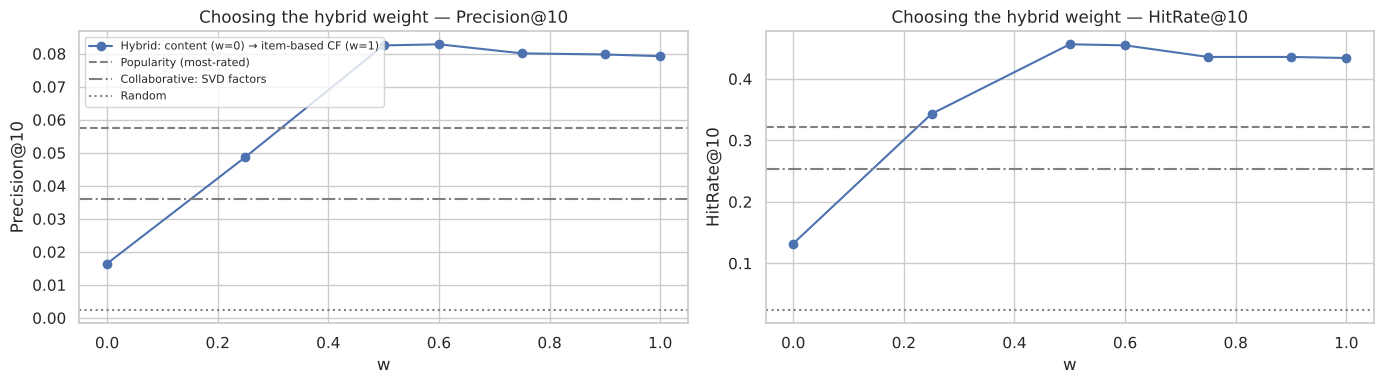

Chosen weight w = 0.5


In [21]:
ws = [0.0] + weights + [1.0]
labels = ["Content: TF-IDF"] + [f"Hybrid w={w}" for w in weights] + ["Collaborative: item-based CF"]
curve = hybrid_eval.loc[labels]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric in zip(axes, ["Precision@10", "HitRate@10"]):
    ax.plot(ws, curve[metric], "o-", label="Hybrid: content (w=0) → item-based CF (w=1)")
    for name, ls in [("Popularity (most-rated)", "--"), ("Collaborative: SVD factors", "-."), ("Random", ":")]:
        ax.axhline(hybrid_eval.loc[name, metric], ls=ls, color="grey", label=name)
    ax.set_xlabel("w"); ax.set_ylabel(metric); ax.set_title(f"Choosing the hybrid weight — {metric}")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# choose w on Hit-rate (more stable than precision with only ~580 users), ties -> more content
best_w = float(ws[int(np.argmax(curve["HitRate@10"].round(3).values))])
print("Chosen weight w =", best_w)

**Reading the results**
- **TF-IDF beats CountVectorizer** for content-based ranking, confirming the choice for `similarity.pkl`,
  and **weighted fields beat equal weights**.
- Pure content-based is weak at predicting what people *actually* watch next: it finds *similar* films,
  not necessarily ones people go on to watch and like.
- **Popularity is a strong baseline** (people do watch famous films), a classic finding in
  recommender research and the reason you should always report one. SVD-factor similarity does *not*
  beat it here: factor cosine ignores how popular or good a film is.
- **Item-based CF clearly beats popularity**, and adding a share of content gives a small extra gain at
  a moderate weight. Content matters even more where the metric can't see it: films with few or no
  ratings (cold start) can only be recommended through content.
- Caveat: differences of a few thousandths in Precision@10 are within noise for ~580 users. The robust
  conclusions are the big gaps (content ≪ popularity < item-CF ≈ hybrid).

### 4.2 Save the hybrid model
Rebuild the item-item matrix from **all** ratings and save it with the TF-IDF matrix and the chosen
weight in `hybrid.pkl`, for the app's "Pick films you love" mode.

In [22]:
item_sim = rec.item_item_similarity(interactions(ml), k=50)
hybrid_artifact = {"tfidf": sparse.csr_matrix(X_tfidf, dtype=np.float32), "item_sim": item_sim,
                   "weight": best_w, "n_rated_films": int(ml.row.nunique()),
                   "eval": hybrid_eval.round(4).to_dict(orient="index")}
pickle.dump(hybrid_artifact, open("hybrid.pkl", "wb"))
print(f"hybrid.pkl: {os.path.getsize('hybrid.pkl') / 1e6:.1f} MB | weight = {best_w}")

hybrid.pkl: 2.6 MB | weight = 0.5


In [23]:
# Try it: someone who loves these three films
liked_titles = ["The Dark Knight", "Inception", "The Matrix"]
liked = [title_to_idx[t] for t in liked_titles]
for label, w in [("Content only", 0.0), ("Collaborative only", 1.0), (f"Hybrid (w={best_w})", best_w)]:
    s = rec.hybrid_scores(liked, hybrid_artifact["tfidf"], item_sim, w); s[liked] = -np.inf
    print(f"--- {label} ---"); print(movies.loc[np.argsort(-s)[:10], "title"].tolist())

--- Content only ---
['The Matrix Reloaded', 'The Matrix Revolutions', 'Batman Begins', 'The Dark Knight Rises', 'Batman Returns', 'The Thirteenth Floor', 'Interstellar', 'Batman v Superman: Dawn of Justice', 'The Helix... Loaded', 'Memento']
--- Collaborative only ---
['Fight Club', 'The Lord of the Rings: The Return of the King', 'The Lord of the Rings: The Fellowship of the Ring', 'The Lord of the Rings: The Two Towers', 'Kill Bill: Vol. 1', 'Pirates of the Caribbean: The Curse of the Black Pearl', 'Memento', 'The Shawshank Redemption', 'Finding Nemo', 'Catch Me If You Can']
--- Hybrid (w=0.5) ---
['The Dark Knight Rises', 'Batman Begins', 'Memento', 'Fight Club', 'The Lord of the Rings: The Return of the King', 'The Lord of the Rings: The Fellowship of the Ring', 'The Lord of the Rings: The Two Towers', 'Kill Bill: Vol. 1', 'Pirates of the Caribbean: The Curse of the Black Pearl', 'Catch Me If You Can']


## 5. Summary

| Part | What was done |
|---|---|
| Data | Merged TMDB movies + credits on `id` (a title merge duplicates rows); replaced the truncated credits file with the full one; parsed the JSON columns |
| Content-based | Tags = overview + genres + keywords + top-3 cast + director; collapsed names, stemmed; TF-IDF (5,000 terms) + cosine similarity; top-50 neighbours saved to `similarity.pkl` |
| Collaborative | MovieLens ratings; user-based CF from scratch (Pearson), surprise KNN and SVD; SVD best on RMSE |
| Hybrid | Content + item-based CF, weight chosen by a time-based Hit-rate@10 / Precision@10 evaluation against random and popularity baselines; saved to `hybrid.pkl` |
| App | Flask app with "Similar films" (content) and "Pick films you love" (hybrid) modes, Dockerised |

**Future improvements:** a logged-in mode using each user's own SVD vector; diversity/novelty
re-ranking; sentence-embedding models for plot text instead of bag-of-words; deploying to a cloud host.